In [1]:
import torch
import torch.nn as nn 
import torch.optim as optim 
import torchvision 
from torchvision.datasets import MNIST

In [3]:
from torch.utils.data import DataLoader
from torchvision.transforms import transforms

transform= transforms.Compose([
    transforms.ToTensor(), 
    transforms.Normalize((0.1307,),(0.3081,))
])

trainset= MNIST(root= "./data", train= True, download=True, transform=transform)
testset= MNIST(root= "./data", train= False, download=True, transform=transform)

In [5]:
trainset

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.1307,), std=(0.3081,))
           )

In [7]:
trainloader= DataLoader(trainset,batch_size=64, shuffle=True)
testloader= DataLoader(testset,batch_size=64)

## CNN model

In [10]:
class CNN(nn.Module):
    def __init__(self): 
        super(CNN, self).__init__()

        self.conv_layers= nn.Sequential(
            nn.Conv2d(1, 32,kernel_size=3, padding= 1), 
            nn.ReLU(), 
            nn.MaxPool2d(2), 

            nn.Conv2d(32, 64,kernel_size=3, padding= 1), 
            nn.ReLU(), 
            nn.MaxPool2d(2),
        )
        self.fc_layers= nn.Sequential(
            nn.Linear(64*7*7, 128), 
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 10) # 10 final o/p's 0 to 9
        )

    def forward(self, x): 
        x= self.conv_layers(x)
        x= x.view(x.size(0), -1)
        x= self.fc_layers(x)

        return x

In [12]:
model= CNN()

In [16]:
criterion =nn.CrossEntropyLoss() 
optimizer= optim.Adam(model.parameters())

In [20]:
# Training our model 
epochs= 5
for epoch in range(epochs): 
    epoch_training_loss= 0.0 
    for image , labels in trainloader: 
        optimizer.zero_grad() 

        output= model.forward(image)
        loss= criterion(output, labels)
        loss.backward()

        optimizer.step()
        epoch_training_loss+= loss.item()

    print(f"epoch={epoch} & loss={epoch_training_loss/len(trainloader)}")

epoch=0 & loss=0.1764061015475589
epoch=1 & loss=0.06165051771857059
epoch=2 & loss=0.043571385634648026
epoch=3 & loss=0.03428970163252189
epoch=4 & loss=0.028135183709810104


In [28]:
# Evaluation 
correct_labels= 0
total_labels= 0

model.eval()
with torch.no_grad(): # nograd stops gradient calculation since we do not need to train ,and zerograd calculates but makes it zero after each iteration.
    for image, labels in testloader: 
        output= model.forward(image) 
        _, predicted= torch.max(output,1) # the outputs 10 probabilities of being each no. 0-9 ,the highest index is choosen here which directly means the no.

        correct_labels+= (predicted==labels).sum().item()
        total_labels+= labels.size(0)

print(f"accuracy= {correct_labels/total_labels*100}")

accuracy= 99.21


In [32]:
# saving the model parameters
torch.save(model.state_dict(),"cnn_model.pth")

In [34]:
# Viewing Confusion matrix 
from sklearn.metrics import confusion_matrix 
import seaborn as sns 
import matplotlib.pyplot as plt

In [38]:
all_preds=[]
all_labels=[]

model.eval()
with torch.no_grad(): 
    for image, labels in testloader: 
        output= model.forward(image) 
        _, preds= torch.max(output,1)  

        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

In [40]:
cm= confusion_matrix(all_labels,all_preds)

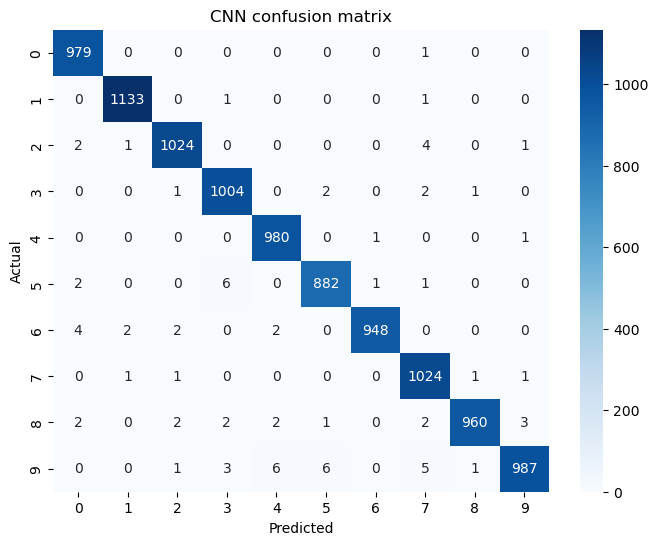

In [44]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True, 
    fmt="d", 
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN confusion matrix")

plt.show()

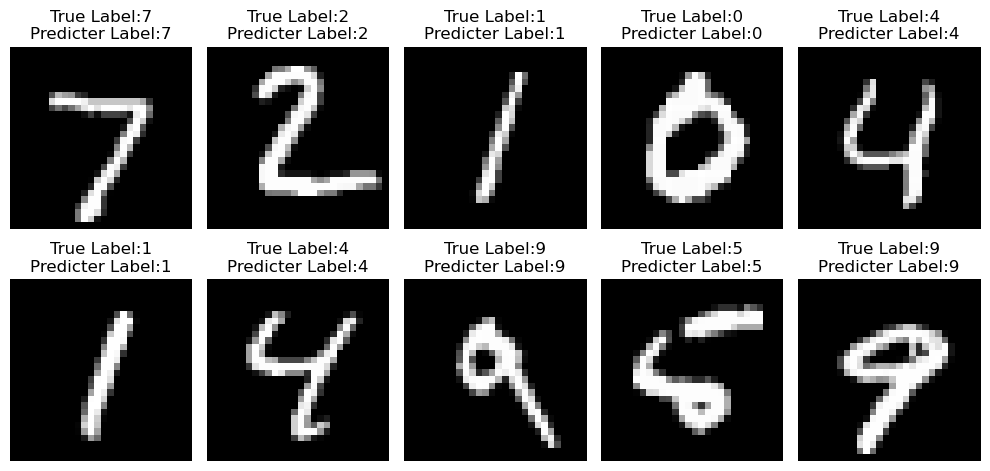

In [50]:
# Visualizng results
model.eval()

images, labels= next(iter(testloader))
with torch.no_grad(): 
    outputs= model(images) 
    _, preds= torch.max(outputs, 1)

fig, axes = plt.subplots(2,5, figsize=(10,5))

for i,ax in enumerate(axes.flat): 
    ax.imshow(images[i].squeeze(), cmap= "gray") # squeezed is to remove channel dimension [1,28,28] to [28,28] since it only takes 2 dimentions
    ax.set_title(f"True Label:{labels[i]}\nPredicter Label:{preds[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()